# LOVAMAP Hypothesis Mining

Systematic analysis of the RDF knowledge base to generate and evaluate
data-driven hypotheses about granular biomaterial engineering.

**Data source:** Local TTL files via rdflib, or Fuseki SPARQL endpoint (toggle `USE_LOCAL` below)

**What this notebook does:**
1. Loads the knowledge base (local TTL files or Fuseki) and provides a `query()` helper
2. Inventories the knowledge base (papers, materials, outcomes, comparisons)
3. Mines comparison results using v3 `aboutMaterial` / `materialA`/`materialB` links
4. Computes material property win rates
5. Builds material-outcome association matrices (heatmap)
6. Identifies gaps (untested combinations) as candidate hypotheses
7. Scores and ranks hypotheses by evidence strength

## Setup & Connection

In [1]:
import json
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from dotenv import load_dotenv
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid')

# ── Toggle: True = load TTL files locally with rdflib, False = query Fuseki ──
USE_LOCAL = True

SEED_DATA_DIR = Path('..') / 'Data' / 'SeedData'

In [2]:
# Standard prefixes — prepended to every query
PREFIXES = """
PREFIX lova:   <https://lovamap.com/ontology#>
PREFIX dc:     <http://purl.org/dc/terms/>
PREFIX foaf:   <http://xmlns.com/foaf/0.1/>
PREFIX schema: <https://schema.org/>
PREFIX rdfs:   <http://www.w3.org/2000/01/rdf-schema#>
PREFIX rdf:    <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX xsd:    <http://www.w3.org/2001/XMLSchema#>
PREFIX text:   <http://jena.apache.org/text#>
PREFIX bibo:   <http://purl.org/ontology/bibo/>
PREFIX qudt:   <http://qudt.org/schema/qudt/>
"""

if USE_LOCAL:
    # ── Local mode: load all TTL files into an rdflib graph ──
    import rdflib

    graph = rdflib.Graph()
    ttl_files = sorted(SEED_DATA_DIR.glob('*.ttl'))
    print(f"Loading {len(ttl_files)} TTL files from {SEED_DATA_DIR.resolve()}...")
    for f in ttl_files:
        graph.parse(f, format='turtle')
    print(f"Loaded {len(graph):,} triples")

    # Some TTL files use dc1: instead of dc: — bind dc: so SPARQL queries work
    graph.bind('dc', rdflib.Namespace('http://purl.org/dc/terms/'))

    def query(sparql: str, limit: int | None = None) -> pd.DataFrame:
        """Run a SPARQL SELECT against the local rdflib graph."""
        full_query = PREFIXES + sparql.strip()
        if limit is not None and 'LIMIT' not in sparql.upper():
            full_query += f"\nLIMIT {limit}"
        results = graph.query(full_query)
        cols = [str(v) for v in results.vars]
        rows = []
        for row in results:
            rows.append({col: str(val) if val is not None else '' for col, val in zip(cols, row)})
        return pd.DataFrame(rows, columns=cols)

else:
    # ── Remote mode: query Fuseki SPARQL endpoint ──
    load_dotenv(Path('..') / '..' / '.env')

    FUSEKI_BASE = os.environ['FUSEKI_URL'].rstrip('/')
    FUSEKI_DATASET = os.environ['FUSEKI_DATASET']
    FUSEKI_USER = 'admin'
    FUSEKI_PASS = os.environ['FUSEKI_ADMIN_PASSWORD']
    FUSEKI_QUERY_URL = f"{FUSEKI_BASE}/{FUSEKI_DATASET}/query"
    print(f"Fuseki endpoint: {FUSEKI_QUERY_URL}")

    def query(sparql: str, limit: int | None = None) -> pd.DataFrame:
        """Run a SPARQL SELECT against Fuseki and return a DataFrame."""
        full_query = PREFIXES + sparql.strip()
        if limit is not None and 'LIMIT' not in sparql.upper():
            full_query += f"\nLIMIT {limit}"
        auth = (FUSEKI_USER, FUSEKI_PASS) if FUSEKI_USER else None
        resp = requests.post(
            FUSEKI_QUERY_URL,
            data=full_query.encode('utf-8'),
            headers={
                'Content-Type': 'application/sparql-query',
                'Accept': 'application/sparql-results+json',
            },
            auth=auth,
            timeout=60,
        )
        resp.raise_for_status()
        data = resp.json()
        cols = data['head']['vars']
        rows = []
        for binding in data['results']['bindings']:
            rows.append({v: binding.get(v, {}).get('value', '') for v in cols})
        return pd.DataFrame(rows, columns=cols)


def local_name(uri: str) -> str:
    """Extract the local name from a URI (after # or last /)."""
    if '#' in uri:
        return uri.split('#', 1)[1]
    return uri.rsplit('/', 1)[-1]


# Quick connectivity test
test = query("SELECT (COUNT(*) AS ?n) WHERE { ?s a bibo:AcademicArticle }")
print(f"Papers in knowledge base: {test.iloc[0]['n']}")

Loading 92 TTL files from /Users/dzen/Documents/LOVAMAP/Repos/LOVAMAP_GW/KnowledgeBaseBackend/Data/SeedData...
Loaded 72,266 triples
Papers in knowledge base: 92


## 1. Knowledge Base Inventory

Quick census of what we're working with.

In [3]:
# Entity counts
inventory = query("""
SELECT 
  (COUNT(DISTINCT ?paper) AS ?papers)
  (COUNT(DISTINCT ?mat) AS ?materials)
  (COUNT(DISTINCT ?exp) AS ?experiments)
  (COUNT(DISTINCT ?out) AS ?outcomes)
  (COUNT(DISTINCT ?cmp) AS ?comparisons)
  (COUNT(DISTINCT ?fab) AS ?fabrication_methods)
  (COUNT(DISTINCT ?rea) AS ?reagents)
WHERE {
  { ?paper a bibo:AcademicArticle } UNION
  { ?mat a lova:Material } UNION
  { ?exp a lova:Experiment } UNION
  { ?out a lova:Outcome } UNION
  { ?cmp a lova:ComparisonResult } UNION
  { ?fab a lova:FabricationMethod } UNION
  { ?rea a lova:Reagent }
}
""")
inventory.T.rename(columns={0: 'count'})

,count
papers,92
materials,652
experiments,905
outcomes,3276
comparisons,859
fabrication_methods,243
reagents,1313


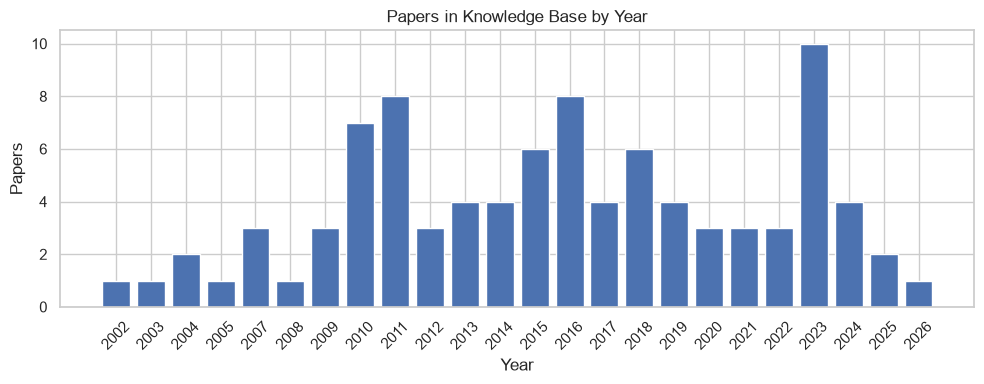

In [4]:
# Papers by year
papers_by_year = query("""
SELECT ?year (COUNT(?paper) AS ?count)
WHERE {
  ?paper a bibo:AcademicArticle ;
         dc:date ?year .
}
GROUP BY ?year
ORDER BY ?year
""")
papers_by_year['count'] = papers_by_year['count'].astype(int)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(papers_by_year['year'], papers_by_year['count'])
ax.set_xlabel('Year')
ax.set_ylabel('Papers')
ax.set_title('Papers in Knowledge Base by Year')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
# Top journals
journals = query("""
SELECT ?journalTitle (COUNT(?paper) AS ?count)
WHERE {
  ?paper a bibo:AcademicArticle ;
         schema:isPartOf ?journal .
  ?journal dc:title ?journalTitle .
}
GROUP BY ?journalTitle
ORDER BY DESC(?count)
""")
journals['count'] = journals['count'].astype(int)
journals

,journalTitle,count
0,Biomaterials,14
1,Acta Biomaterialia,6
2,Advanced Healthcare Materials,6
3,Advanced Materials,6
4,Nature Materials,4
5,Advanced Functional Materials,3
6,Journal of Controlled Release,3
7,Bioconjugate Chemistry,3
8,Biomacromolecules,3
9,Small,3


## 2. Comparison Mining: Which Materials Win?

The core of hypothesis generation. Each `ComparisonResult` tells us that outcomeA was
higher/lower than outcomeB, and whether this was statistically significant.

We trace each comparison back to the materials and their properties to find
which material features are most frequently associated with "winning."

In [6]:
# Load all comparisons with material properties using v3 direct links
# v3 uses lova:materialA/materialB on ComparisonResult and lova:aboutMaterial on Outcome
# — no more ambiguous experiment → usedMaterial trace
comparisons = query("""
SELECT ?cmp ?cmpLabel ?direction ?significant ?pValue
       ?outA ?outALabel ?measTypeA ?measCatA
       ?outB ?outBLabel
       ?matA ?matALabel ?particleMaterialA ?particleShapeA ?packingA ?surfaceModA ?stiffnessA ?stiffnessUnitA ?sizeMinA ?sizeMaxA
       ?matB ?matBLabel ?particleMaterialB ?particleShapeB ?packingB ?surfaceModB ?stiffnessB ?stiffnessUnitB ?sizeMinB ?sizeMaxB
       ?paperTitle ?doi
WHERE {
  ?cmp a lova:ComparisonResult ;
       rdfs:label ?cmpLabel ;
       lova:direction ?direction ;
       lova:outcomeA ?outA ;
       lova:outcomeB ?outB ;
       dc:source ?paper .

  ?paper dc:title ?paperTitle ;
         dc:identifier ?doi .

  OPTIONAL { ?cmp lova:isSignificant ?significant }
  OPTIONAL { ?cmp lova:pValue ?pValue }

  ?outA rdfs:label ?outALabel .
  OPTIONAL { ?outA lova:measurementType ?measTypeA }
  OPTIONAL { ?outA lova:measurementCategory ?measCatA }

  ?outB rdfs:label ?outBLabel .

  # v3: direct material links on ComparisonResult
  OPTIONAL {
    ?cmp lova:materialA ?matA .
    ?matA rdfs:label ?matALabel .
    OPTIONAL { ?matA lova:particleMaterial ?particleMaterialA }
    OPTIONAL { ?matA lova:particleShape ?particleShapeA }
    OPTIONAL { ?matA lova:packingConfiguration ?packingA }
    OPTIONAL { ?matA lova:surfaceModification ?surfaceModA }
    OPTIONAL { ?matA lova:stiffnessValue ?stiffnessA }
    OPTIONAL { ?matA lova:stiffnessUnit ?stiffnessUnitA }
    OPTIONAL { ?matA lova:particleSizeMin ?sizeMinA }
    OPTIONAL { ?matA lova:particleSizeMax ?sizeMaxA }
  }

  OPTIONAL {
    ?cmp lova:materialB ?matB .
    ?matB rdfs:label ?matBLabel .
    OPTIONAL { ?matB lova:particleMaterial ?particleMaterialB }
    OPTIONAL { ?matB lova:particleShape ?particleShapeB }
    OPTIONAL { ?matB lova:packingConfiguration ?packingB }
    OPTIONAL { ?matB lova:surfaceModification ?surfaceModB }
    OPTIONAL { ?matB lova:stiffnessValue ?stiffnessB }
    OPTIONAL { ?matB lova:stiffnessUnit ?stiffnessUnitB }
    OPTIONAL { ?matB lova:particleSizeMin ?sizeMinB }
    OPTIONAL { ?matB lova:particleSizeMax ?sizeMaxB }
  }
}
""")

print(f"Total comparison rows: {len(comparisons)}")
print(f"Unique comparisons: {comparisons['cmp'].nunique()}")
print(f"\nDirection distribution:")
print(comparisons['direction'].value_counts())
print(f"\nSignificant: {comparisons['significant'].value_counts().to_dict()}")

Total comparison rows: 853
Unique comparisons: 853

Direction distribution:
direction
higher           531
lower            231
no difference     91
Name: count, dtype: int64

Significant: {'true': 536, '': 246, 'false': 71}


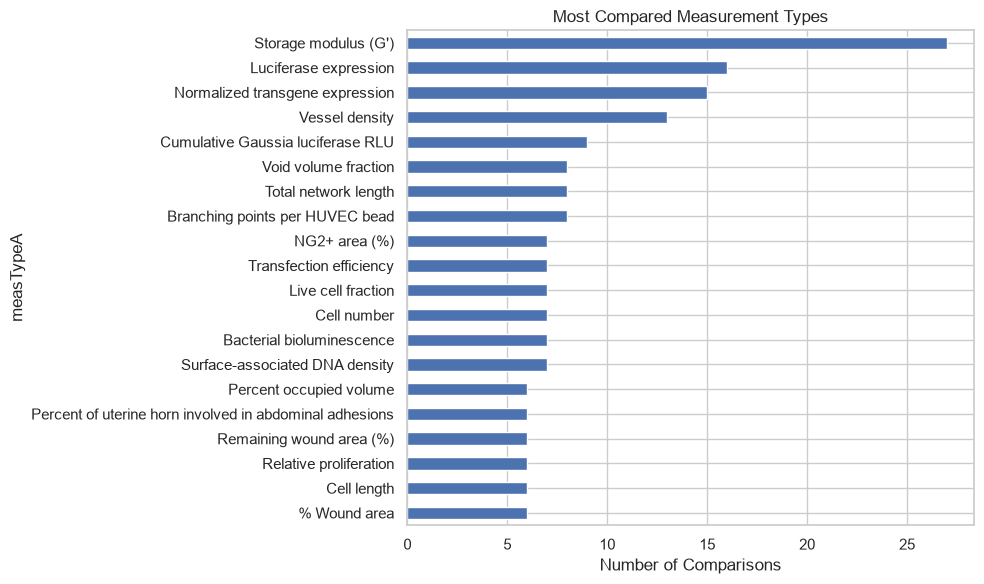

In [7]:
# What measurement types are most compared?
meas_type_counts = comparisons.groupby('measTypeA')['cmp'].nunique().sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(10, 6))
meas_type_counts.plot.barh(ax=ax)
ax.set_xlabel('Number of Comparisons')
ax.set_title('Most Compared Measurement Types')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 3. Material Property Win Rates

For each material property (particle material, shape, packing, surface modification),
compute how often it appears on the "winning" side of significant comparisons.

In [8]:
# Filter to significant comparisons with a clear direction
sig = comparisons[
    (comparisons['significant'] == 'true') &
    (comparisons['direction'].isin(['higher', 'lower']))
].copy()

print(f"Significant directional comparisons: {sig['cmp'].nunique()}")

def win_rate_analysis(df, property_col_a, property_col_b, property_name):
    """Compute win rates for a material property.
    
    A 'win' means the material property appeared on the outcomeA side
    (the favored side per the comparison direction).
    """
    # Count appearances on winner side (outcomeA)
    wins = df[df[property_col_a] != ''][property_col_a].value_counts()
    
    # Count appearances on loser side (outcomeB) 
    losses = df[df[property_col_b] != ''][property_col_b].value_counts()
    
    # Combine
    all_vals = set(wins.index) | set(losses.index)
    results = []
    for val in all_vals:
        w = wins.get(val, 0)
        l = losses.get(val, 0)
        total = w + l
        results.append({
            property_name: val,
            'wins': w,
            'losses': l,
            'total': total,
            'win_rate': w / total if total > 0 else 0,
        })
    
    return pd.DataFrame(results).sort_values('total', ascending=False)


# Particle material win rates
mat_wins = win_rate_analysis(sig, 'particleMaterialA', 'particleMaterialB', 'particleMaterial')
print("\n=== Particle Material Win Rates (min 5 comparisons) ===")
display(mat_wins[mat_wins['total'] >= 5].head(15))

Significant directional comparisons: 531

=== Particle Material Win Rates (min 5 comparisons) ===


,particleMaterial,wins,losses,total,win_rate
23,HA-AC,88,72,160,0.550000
36,HA-NB,55,59,114,0.482456
58,HA,49,48,97,0.505155
14,PEG-VS,26,28,54,0.481481
49,Heparin,20,16,36,0.555556
4,Polystyrene,14,16,30,0.466667
43,PEG-PPS,13,13,26,0.500000
11,Fibronectin,12,12,24,0.500000
53,Titanium,12,10,22,0.545455
59,Fibrin,8,14,22,0.363636


In [9]:
# Packing configuration win rates
packing_wins = win_rate_analysis(sig, 'packingA', 'packingB', 'packing')
print("=== Packing Configuration Win Rates (min 3 comparisons) ===")
display(packing_wins[packing_wins['total'] >= 3])

=== Packing Configuration Win Rates (min 3 comparisons) ===


,packing,wins,losses,total,win_rate
8,Jammed,100,100,200,0.500000
3,Random,23,9,32,0.718750
0,Non-porous,13,9,22,0.590909
9,Hexagonal,8,13,21,0.380952
1,2D,9,3,12,0.750000
7,Clustered (10μL gel clusters),4,3,7,0.571429
6,Flowable liquid (non-particulate),3,0,3,1.000000


In [10]:
# Particle shape win rates
shape_wins = win_rate_analysis(sig, 'particleShapeA', 'particleShapeB', 'particleShape')
print("=== Particle Shape Win Rates (min 3 comparisons) ===")
display(shape_wins[shape_wins['total'] >= 3])

=== Particle Shape Win Rates (min 3 comparisons) ===


,particleShape,wins,losses,total,win_rate
1,Sphere,167,155,322,0.518634
0,Irregular,15,12,27,0.555556
2,Wire/pin,10,10,20,0.500000
6,Wire (L-shaped implant),7,7,14,0.500000
8,Spherical,6,6,12,0.500000
3,Spherical micelle,7,4,11,0.636364
5,Complex (polyplex),3,3,6,0.500000
7,Ring/doughnut,5,0,5,1.000000


In [11]:
# Surface modification win rates
surf_wins = win_rate_analysis(sig, 'surfaceModA', 'surfaceModB', 'surfaceModification')
print("=== Surface Modification Win Rates (min 3 comparisons) ===")
display(surf_wins[surf_wins['total'] >= 3])

=== Surface Modification Win Rates (min 3 comparisons) ===


,surfaceModification,wins,losses,total,win_rate
53,RGD-functionalized,18,18,36,0.500000
71,"VEGF covalently bound via photoactive crosslinker ABH, high or low binding d...",10,9,19,0.526316
8,RGD-functionalized (Ac-RGDSPGERCG-NH2),9,9,18,0.500000
38,Unmodified (native),1,11,12,0.083333
48,RGD-coated,10,2,12,0.833333
41,Citrullinated (PAD2+PAD4 treated),11,1,12,0.916667
73,"Heparin-coated (photoactive crosslinker ABH), VEGF bound covalently (Vc) or ...",6,6,12,0.500000
33,RGD-modified (Ac-GCGYGRGDSPG-NH2),5,6,11,0.454545
43,"RGD 10 μM, homogeneous (condition 1, least clustered)",10,0,10,1.000000
31,"RGD 100μM, YIGSR 48μM, IKVAV 300μM (DOE-optimized concentrations)",6,3,9,0.666667


## 4. Material-Outcome Association Matrix

Cross-tabulation: rows = material properties, columns = biological outcome categories.
Cells = count of significant positive comparisons. Heatmap reveals where the evidence is
concentrated and where the gaps (hypotheses) are.

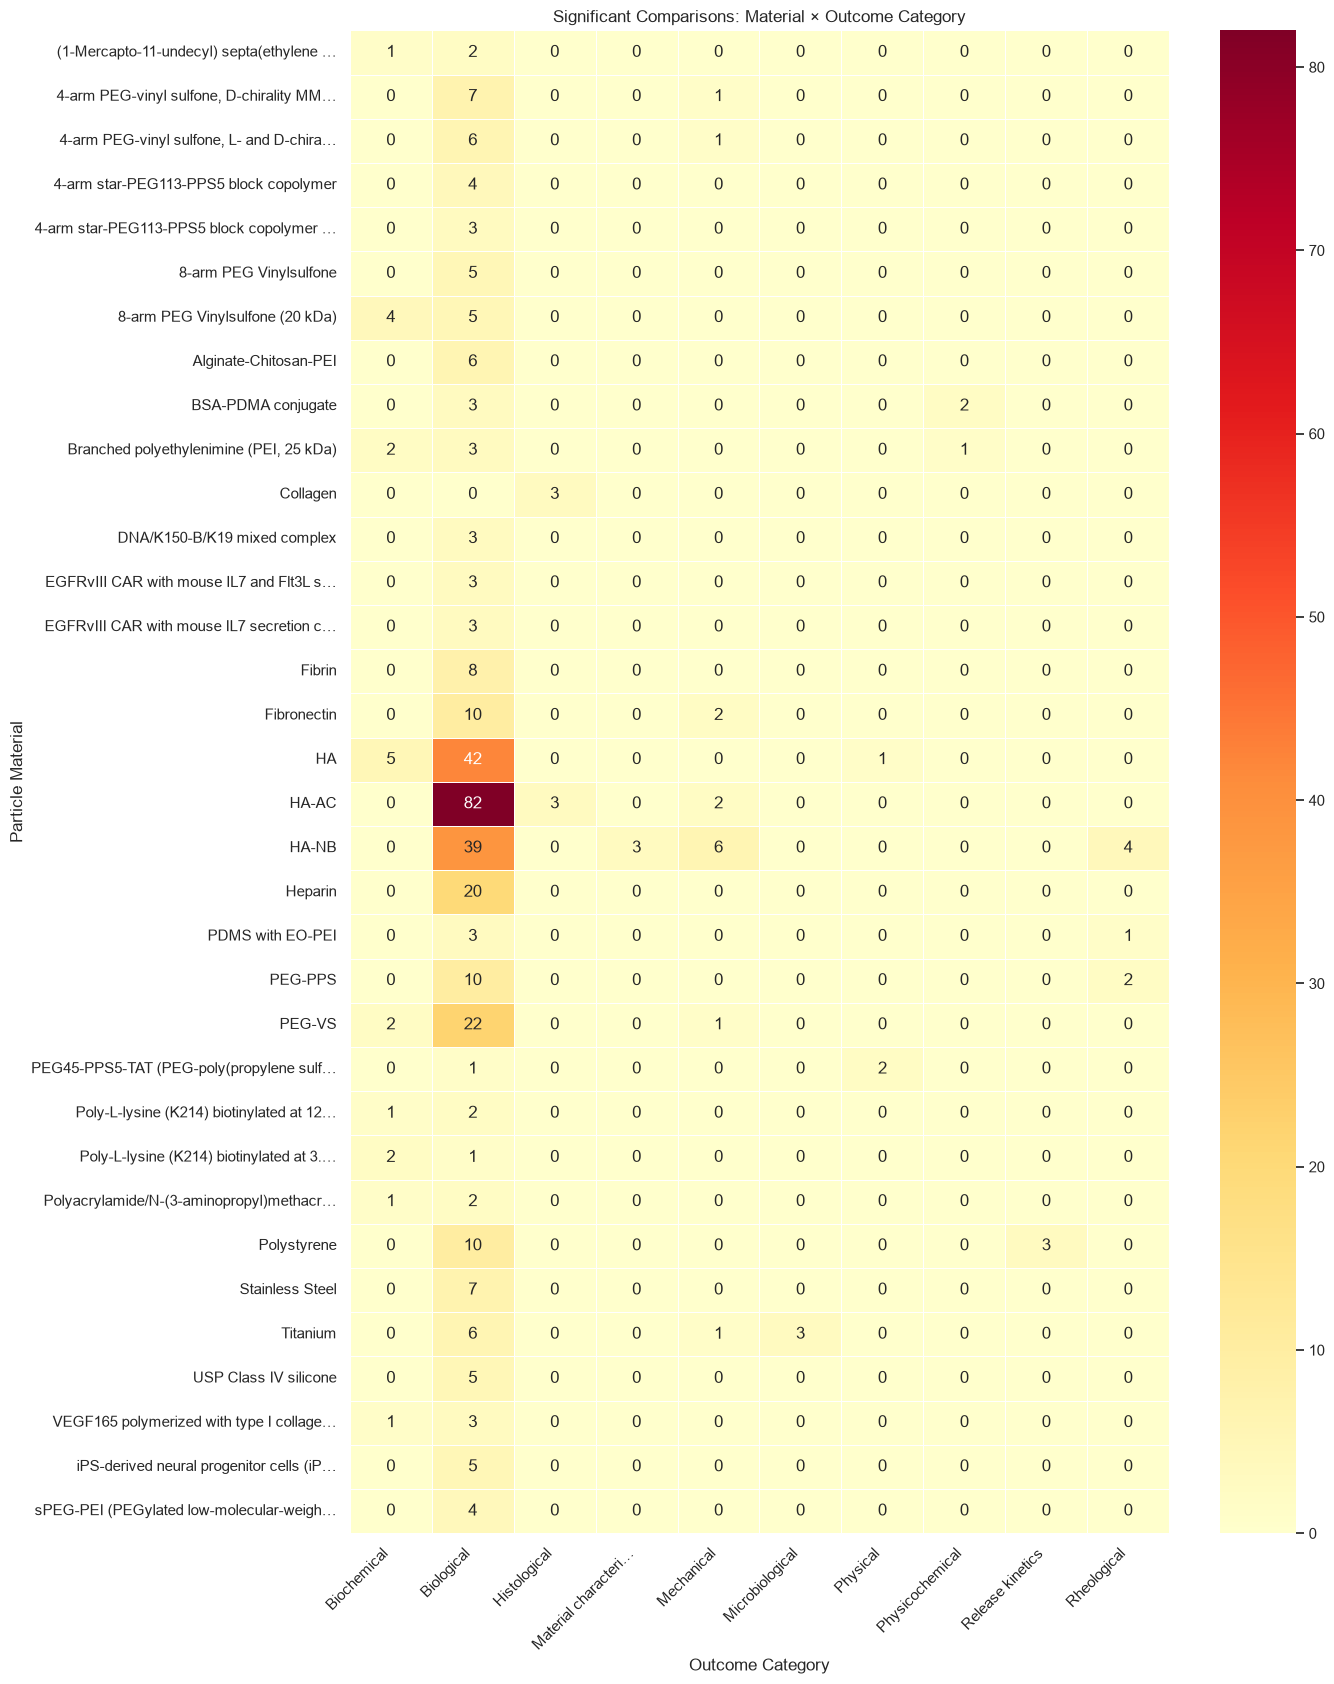

In [12]:
# Build the matrix: particleMaterial vs measurementCategory
sig_with_data = sig[
  (sig['particleMaterialA'] != '') &
  (sig['measCatA'] != '')
].copy()

matrix = sig_with_data.groupby(
  ['particleMaterialA', 'measCatA']
)['cmp'].nunique().reset_index()
matrix.columns = ['material', 'outcome_category', 'sig_comparisons']

pivot = matrix.pivot_table(
  index='material', columns='outcome_category',
  values='sig_comparisons', fill_value=0
)

# Filter to materials and categories with enough data
min_comparisons = 3
pivot_filtered = pivot.loc[
  pivot.sum(axis=1) >= min_comparisons,
  pivot.sum(axis=0) >= min_comparisons
]

def truncate(label, max_len=40):
  return label if len(label) <= max_len else label[:max_len-1] + '…'

if not pivot_filtered.empty:
  plot_df = pivot_filtered.copy()
  plot_df.index = [truncate(s) for s in plot_df.index]
  plot_df.columns = [truncate(s, 20) for s in plot_df.columns]

  fig, ax = plt.subplots(figsize=(14, max(8, len(plot_df) * 0.5)))
  sns.heatmap(plot_df, annot=True, fmt='g', cmap='YlOrRd', ax=ax,
              linewidths=0.5, linecolor='white')
  ax.set_title('Significant Comparisons: Material × Outcome Category')
  ax.set_xlabel('Outcome Category')
  ax.set_ylabel('Particle Material')
  plt.xticks(rotation=45, ha='right')
  plt.yticks(rotation=0)
  plt.tight_layout()
  plt.show()
else:
  print("Not enough data for heatmap — try lowering min_comparisons")
  display(pivot)

## 5. Fabrication Method Analysis

Which fabrication chemistries and manufacturing methods are associated with the best outcomes?

In [13]:
# Fabrication methods linked to winning materials (v3: use aboutMaterial)
fab_comparisons = query("""
SELECT ?cmp ?direction ?significant ?measType ?measCat
       ?chemistry ?mfgMethod ?annealingChem
       ?paperTitle
WHERE {
  ?cmp a lova:ComparisonResult ;
       lova:direction ?direction ;
       lova:outcomeA ?outA ;
       lova:materialA ?matA ;
       dc:source ?paper .

  ?paper dc:title ?paperTitle .
  OPTIONAL { ?cmp lova:isSignificant ?significant }
  OPTIONAL { ?outA lova:measurementType ?measType }
  OPTIONAL { ?outA lova:measurementCategory ?measCat }

  ?matA lova:hasFabricationMethod ?fab .

  OPTIONAL { ?fab lova:chemistry ?chemistry }
  OPTIONAL { ?fab lova:manufacturingMethod ?mfgMethod }
  OPTIONAL { ?fab lova:annealingChemistry ?annealingChem }
}
""")

print(f"Comparisons with fabrication data: {fab_comparisons['cmp'].nunique()}")

# Annealing chemistry win rates (important for MAP scaffolds)
fab_sig = fab_comparisons[fab_comparisons['significant'] == 'true'].copy()
if not fab_sig.empty:
    anneal_counts = fab_sig[fab_sig['annealingChem'] != ''].groupby('annealingChem')['cmp'].nunique()
    anneal_counts = anneal_counts.sort_values(ascending=False).head(10)
    print("\n=== Annealing Chemistries in Significant Winning Comparisons ===")
    display(anneal_counts.to_frame('sig_wins'))

Comparisons with fabrication data: 717

=== Annealing Chemistries in Significant Winning Comparisons ===


,sig_wins
annealingChem,
Enzymatic (FXIIIa),88
Tetrazine-NB click,38
Disulfide,20
Michael addition,17
Biotin-neutravidin,14
UV photoactivation (365 nm) of azidobenzyl hydrazide crosslinker for VEGF binding,10
UV-activated thiol-ene conjugation forming amphiphilic block copolymer on implant surface,10
MMP-degradable or MMP-nondegradable peptide crosslinking,7
UV photoactivation (365 nm) of azidobenzyl hydrazide crosslinker,6


In [14]:
# Manufacturing method frequency in significant wins
if not fab_sig.empty:
    mfg_counts = fab_sig[fab_sig['mfgMethod'] != ''].groupby('mfgMethod')['cmp'].nunique()
    mfg_counts = mfg_counts.sort_values(ascending=False).head(10)
    print("=== Manufacturing Methods in Significant Winning Comparisons ===")
    display(mfg_counts.to_frame('sig_wins'))

=== Manufacturing Methods in Significant Winning Comparisons ===


,sig_wins
mfgMethod,
Microfluidic water-in-oil emulsion,39
Microfluidic flow-focusing water-in-oil emulsion,17
Jammed HMP packing followed by crosslinker addition and incubation,16
"Solution casting between Sigmacote-functionalized glass coverslips, gelation 30 min at 37°C",15
Microfluidic water-in-oil emulsion (flow focusing),15
Solution mixing / bulk gelation between glass coverslips,12
"Bulk cast, in situ gelation",11
"Incubation in PAD reaction buffer (100mM Tris-HCl, 5mM CaCl2, 0.3mg/mL protein, pH 7.4) with PAD2/PAD4 overnight at room temperature, 200 rpm shaking, quenched with 20mM EDTA",11
Inverse (water-in-hexane) emulsion sonication,10


## 6. Cross-Paper Consistency

A hypothesis is stronger when the same pattern appears across multiple independent papers.
Find material properties that win in 3+ different papers.

In [15]:
# For each particleMaterial on the winning side, count distinct papers
cross_paper = sig[
    sig['particleMaterialA'] != ''
].groupby('particleMaterialA').agg(
    papers=('doi', 'nunique'),
    sig_wins=('cmp', 'nunique'),
).sort_values('papers', ascending=False)

print("=== Material Wins Across Multiple Papers ===")
display(cross_paper[cross_paper['papers'] >= 2].head(15))

=== Material Wins Across Multiple Papers ===


,papers,sig_wins
particleMaterialA,,
HA-AC,14,88
HA,8,49
HA-NB,8,55
PEG-VS,6,26
Heparin,5,20
Polystyrene,2,14
PEG-PPS,2,13
Fibrin,2,8
Titanium,2,12


## 7. Gap Analysis: Untested Combinations

Find material × outcome combinations that have never been tested.
These are candidate hypotheses: "Material X has shown strong performance for outcome Y,
but has never been tested for outcome Z."

In [16]:
# All material-outcome combinations that have been tested (v3: use aboutMaterial)
tested = query("""
SELECT DISTINCT ?particleMaterial ?measCat
WHERE {
  ?out a lova:Outcome ;
       lova:measurementCategory ?measCat ;
       lova:aboutMaterial ?mat .
  ?mat lova:particleMaterial ?particleMaterial .
}
""")

# Get top materials (by number of outcomes) and top outcome categories
top_materials = tested['particleMaterial'].value_counts().head(15).index.tolist()
top_categories = tested['measCat'].value_counts().head(10).index.tolist()

# Build full matrix of possible combinations
tested_set = set(zip(tested['particleMaterial'], tested['measCat']))

gaps = []
for mat in top_materials:
    for cat in top_categories:
        if (mat, cat) not in tested_set:
            gaps.append({'material': mat, 'outcome_category': cat})

gaps_df = pd.DataFrame(gaps)
print(f"Untested combinations among top materials × top outcomes: {len(gaps_df)}")
if not gaps_df.empty:
    display(gaps_df)

Untested combinations among top materials × top outcomes: 75


,material,outcome_category
0,HA-NB,Imaging
1,HA,Chemical
2,HA,Imaging
3,PEG-VS,Physicochemical
4,PEG-VS,Chemical
5,PEG-VS,Material characterization
6,Hyaluronic acid + rat tail collagen,Physicochemical
7,Hyaluronic acid + rat tail collagen,Rheological
8,Hyaluronic acid + rat tail collagen,Chemical
9,Hyaluronic acid + rat tail collagen,Imaging


## 8. Hypothesis Scoring

Score each potential hypothesis by combining:
- **Evidence strength**: number of significant wins
- **Cross-paper support**: wins spanning multiple papers
- **Consistency**: win rate (wins / total comparisons)
- **Biological breadth**: wins across different outcome categories

In [17]:
# Score each material by its overall evidence profile
material_scores = sig[
  sig['particleMaterialA'] != ''
].groupby('particleMaterialA').agg(
  sig_wins=('cmp', 'nunique'),
  papers=('doi', 'nunique'),
  outcome_categories=('measCatA', 'nunique'),
).reset_index()

# Add total comparisons (wins + losses) for win rate
total_as_a = sig[sig['particleMaterialA'] != ''].groupby('particleMaterialA')['cmp'].nunique()
total_as_b = sig[sig['particleMaterialB'] != ''].groupby('particleMaterialB')['cmp'].nunique()
total_appearances = (total_as_a.add(total_as_b, fill_value=0)).rename('total_comparisons')

material_scores = material_scores.merge(
  total_appearances.reset_index(),
  left_on='particleMaterialA', right_on='particleMaterialA',
  how='left'
)

material_scores['win_rate'] = (
  material_scores['sig_wins'] / material_scores['total_comparisons']
)

# Composite score: win_rate * log(papers+1) * log(sig_wins+1) * outcome_breadth_bonus
material_scores['score'] = (
  material_scores['win_rate']
  * np.log1p(material_scores['papers'])
  * np.log1p(material_scores['sig_wins'])
  * np.log1p(material_scores['outcome_categories'])
)

material_scores = material_scores.sort_values('score', ascending=False)

print("=== Material Hypothesis Ranking ===")
print("Higher score = more evidence that this material consistently outperforms\n")
result = material_scores[material_scores['sig_wins'] >= 3].head(15).copy()
result['win_rate'] = result['win_rate'].map('{:.1%}'.format)
result['score'] = result['score'].map('{:.2f}'.format)
display(result)


=== Material Hypothesis Ranking ===
Higher score = more evidence that this material consistently outperforms



,particleMaterialA,sig_wins,papers,outcome_categories,total_comparisons,win_rate,score
23,HA-AC,88,14,4,160.0,55.0%,10.76
24,HA-NB,55,8,6,114.0,48.2%,8.30
22,HA,49,8,4,97.0,50.5%,6.99
35,PEG-VS,26,6,4,54.0,48.1%,4.97
53,Titanium,12,2,4,22.0,54.5%,2.47
25,Heparin,20,5,1,36.0,55.6%,2.10
34,PEG-PPS,13,2,3,26.0,50.0%,2.01
51,Polystyrene,14,2,3,30.0,46.7%,1.92
2,"4-arm PEG-vinyl sulfone, D-chirality MMP crosslinker",8,1,2,9.0,88.9%,1.49
0,(1-Mercapto-11-undecyl) septa(ethylene glycol) amine mixed SAM on gold,3,1,2,3.0,100.0%,1.06


## 9. Explore Further

Use the `query()` function to run any SPARQL query against the knowledge base.
Prefixes are added automatically.

```python
# Example: find all outcomes for a specific material (v3: aboutMaterial)
df = query("""
SELECT ?outLabel ?measType ?value ?unit ?expLabel
WHERE {
  ?mat a lova:Material ;
       lova:particleMaterial "PEG-VS" .
  ?out lova:aboutMaterial ?mat ;
       rdfs:label ?outLabel .
  OPTIONAL { ?out lova:measurementType ?measType }
  OPTIONAL { ?out qudt:numericValue ?value }
  OPTIONAL { ?out qudt:unit ?unit }
  OPTIONAL {
    ?out lova:fromExperiment ?exp .
    ?exp rdfs:label ?expLabel
  }
}
ORDER BY ?measType
""")
```

In [18]:
%run -i export_results.py

Exported to /Users/dzen/Documents/LOVAMAP/Repos/LOVAMAP_GW/KnowledgeBaseBackend/Research/results.html
